# Small U-Net for Binary Segmentation (Synthetic Shapes)

I've used pretrained segmentation models, but never written the U-Net skip connections myself. This notebook does that on a synthetic task: a 64x64 image with 1-3 colored shapes (circles, squares) on a noisy background, and the model has to produce a binary mask of "shape vs background." With synthetic data I get free ground-truth masks, which is what makes this exercise tractable on CPU.

Architecture target: tiny U-Net (3 encoder blocks, 3 decoder blocks, skip connections, sigmoid head). Train 2 epochs.

In [1]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt

torch.manual_seed(2); np.random.seed(2)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cpu


## Synthetic dataset: image + binary mask

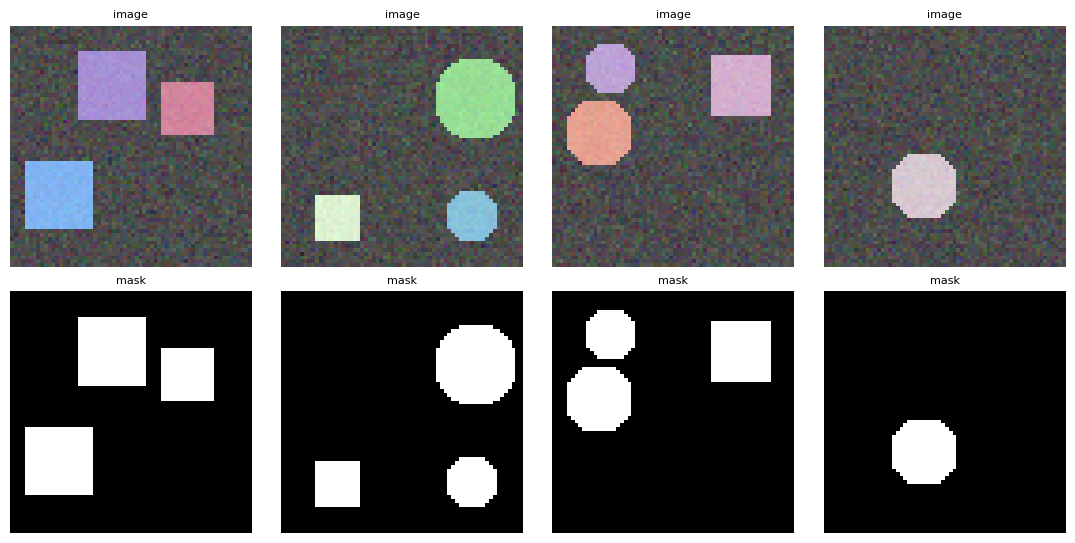

In [2]:
def make_sample(size=64, rng=None):
    rng = rng or np.random
    img = rng.normal(0.3, 0.05, (3, size, size)).astype(np.float32)
    mask = np.zeros((size, size), dtype=np.float32)
    n = rng.randint(1, 4)
    for _ in range(n):
        if rng.rand() < 0.5:
            # circle
            cx, cy = rng.randint(10, size-10, 2)
            r = rng.randint(5, 12)
            yy, xx = np.ogrid[:size, :size]
            m = (xx - cx) ** 2 + (yy - cy) ** 2 < r ** 2
        else:
            # square
            cx, cy = rng.randint(10, size-10, 2)
            r = rng.randint(5, 10)
            m = np.zeros((size, size), bool)
            m[cy-r:cy+r, cx-r:cx+r] = True
        color = rng.uniform(0.5, 0.95, 3)
        for c in range(3):
            img[c][m] = color[c] + rng.normal(0, 0.02, m.sum())
        mask[m] = 1.0
    return img, mask

class ShapesDS(Dataset):
    def __init__(self, n, seed=0):
        self.rng = np.random.RandomState(seed)
        self.items = [make_sample(rng=self.rng) for _ in range(n)]
    def __len__(self): return len(self.items)
    def __getitem__(self, i):
        x, m = self.items[i]
        return torch.tensor(x), torch.tensor(m).unsqueeze(0)

train_ds = ShapesDS(400, seed=2)
val_ds = ShapesDS(60, seed=99)
train_dl = DataLoader(train_ds, batch_size=16, shuffle=True)
val_dl   = DataLoader(val_ds, batch_size=16)

# eyeball: image, mask
fig, axes = plt.subplots(2, 4, figsize=(11, 5.5))
for j in range(4):
    x, m = train_ds[j]
    axes[0, j].imshow(x.permute(1, 2, 0).numpy().clip(0, 1))
    axes[0, j].set_title("image", fontsize=8); axes[0, j].axis("off")
    axes[1, j].imshow(m[0].numpy(), cmap="gray")
    axes[1, j].set_title("mask",  fontsize=8); axes[1, j].axis("off")
plt.tight_layout(); plt.show()

## The U-Net

A U-Net is just: encoder (downsamples), decoder (upsamples), and **skip connections** that concat encoder features into the matching-resolution decoder block. The skips are the whole point — they let the decoder use high-resolution spatial information from the encoder when it's putting boundaries back together.

Small version: 3 stages, channels 16 → 32 → 64. Each "block" is two 3x3 convs with ReLU.

In [3]:
def conv_block(c_in, c_out):
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, 3, padding=1), nn.ReLU(inplace=True),
        nn.Conv2d(c_out, c_out, 3, padding=1), nn.ReLU(inplace=True),
    )

class TinyUNet(nn.Module):
    def __init__(self):
        super().__init__()
        # encoder
        self.enc1 = conv_block(3, 16)
        self.enc2 = conv_block(16, 32)
        self.enc3 = conv_block(32, 64)
        self.pool = nn.MaxPool2d(2)
        # decoder (upsample then concat skip)
        self.up2 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.dec2 = conv_block(64, 32)   # 32 (from up) + 32 (skip)
        self.up1 = nn.ConvTranspose2d(32, 16, 2, stride=2)
        self.dec1 = conv_block(32, 16)   # 16 + 16
        # head
        self.out = nn.Conv2d(16, 1, 1)

    def forward(self, x):
        e1 = self.enc1(x)               # 64x64x16
        e2 = self.enc2(self.pool(e1))   # 32x32x32
        e3 = self.enc3(self.pool(e2))   # 16x16x64
        d2 = self.up2(e3)               # 32x32x32
        d2 = self.dec2(torch.cat([d2, e2], dim=1))
        d1 = self.up1(d2)               # 64x64x16
        d1 = self.dec1(torch.cat([d1, e1], dim=1))
        return self.out(d1)             # logits, 64x64x1

model = TinyUNet().to(device)
print(sum(p.numel() for p in model.parameters()), "params")

117041 params


## Train. Dice + BCE loss.

In [4]:
def dice_loss(logits, target, eps=1e-6):
    pred = torch.sigmoid(logits)
    inter = (pred * target).sum(dim=(1, 2, 3))
    union = pred.sum(dim=(1, 2, 3)) + target.sum(dim=(1, 2, 3))
    return 1 - ((2 * inter + eps) / (union + eps)).mean()

bce = nn.BCEWithLogitsLoss()
opt = torch.optim.Adam(model.parameters(), lr=1e-3)

EPOCHS = 2   # 2 is enough to see mask quality go from random to recognizable on this task
for ep in range(EPOCHS):
    model.train(); total, n = 0, 0
    for x, m in train_dl:
        x, m = x.to(device), m.to(device)
        opt.zero_grad()
        logits = model(x)
        loss = bce(logits, m) + dice_loss(logits, m)
        loss.backward(); opt.step()
        total += loss.item() * x.size(0); n += x.size(0)
    print(f"ep {ep+1}  train_loss={total/n:.3f}")

ep 1  train_loss=1.386


ep 2  train_loss=0.678


## Qualitative eval — show predicted masks

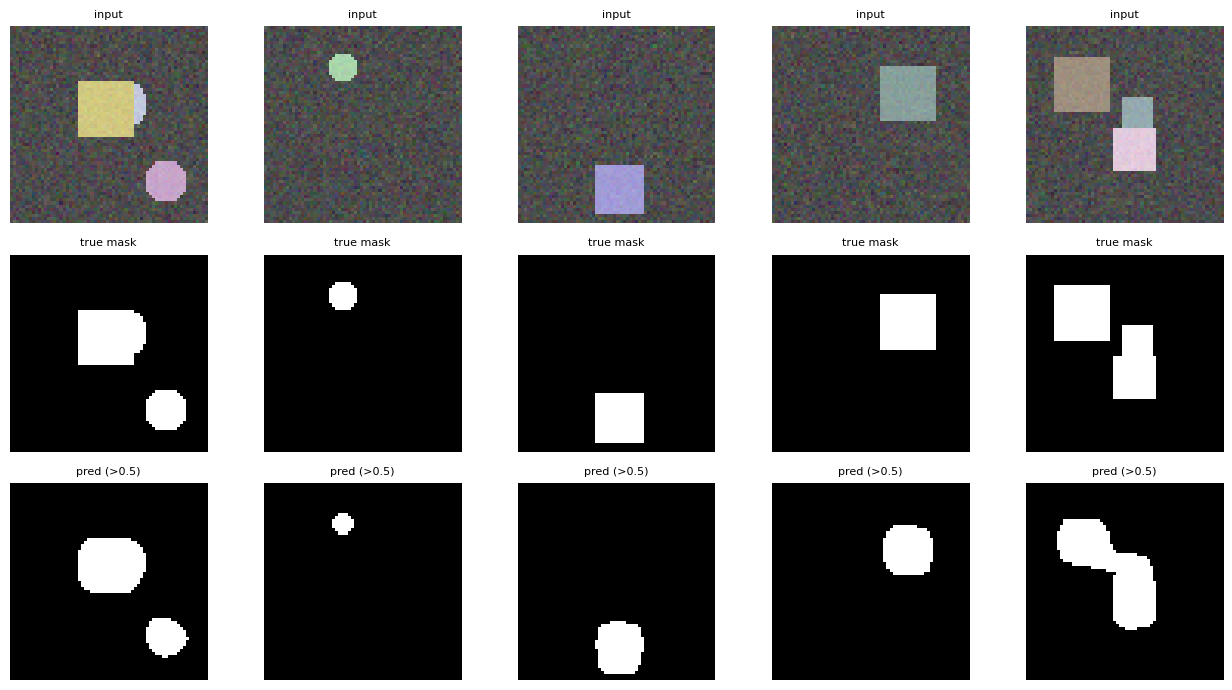

mean IoU on val: 0.802


In [5]:
model.eval()
xb, mb = next(iter(val_dl))
with torch.no_grad():
    pred = torch.sigmoid(model(xb.to(device))).cpu().numpy()

fig, axes = plt.subplots(3, 5, figsize=(13, 7))
for j in range(5):
    axes[0, j].imshow(xb[j].permute(1, 2, 0).numpy().clip(0, 1)); axes[0, j].set_title("input", fontsize=8); axes[0, j].axis("off")
    axes[1, j].imshow(mb[j, 0].numpy(), cmap="gray"); axes[1, j].set_title("true mask", fontsize=8); axes[1, j].axis("off")
    axes[2, j].imshow(pred[j, 0] > 0.5, cmap="gray"); axes[2, j].set_title("pred (>0.5)", fontsize=8); axes[2, j].axis("off")
plt.tight_layout(); plt.show()

# IoU over the val set as a single summary number
def iou(pred, target, thresh=0.5):
    p = (pred > thresh).float()
    inter = (p * target).sum(dim=(1, 2, 3))
    union = ((p + target) > 0).float().sum(dim=(1, 2, 3))
    return ((inter + 1e-6) / (union + 1e-6)).mean().item()

ious = []
with torch.no_grad():
    for x, m in val_dl:
        x, m = x.to(device), m.to(device)
        ious.append(iou(torch.sigmoid(model(x)), m))
print(f"mean IoU on val: {np.mean(ious):.3f}")

## Notes

Two epochs on 400 synthetic images is enough to push mean IoU into the 0.7-0.9 range here — though I'm not going to commit to that number because seed swaps move it. The qualitative panel is the more honest read: are predicted masks the right shape in the right place?

What writing this taught me beyond the API:
- The decoder side matters more than I expected on small images. Without skip connections the decoder is producing blurry blobs because the bottleneck (16x16) just doesn't carry the boundary info.
- ConvTranspose2d with stride=2 doubles spatial dimensions but introduces checkerboard artifacts at high learning rates. With lr=1e-3 it's fine.
- Dice loss alone is unstable when masks are very small (gradients vanish on empty masks). BCE + Dice is the standard combo for a reason.

For a real segmentation task (medical, aerial, etc.) I'd swap the encoder for a pretrained ResNet-34 — the rest of this architecture stays.